In [1]:

import subprocess
subprocess.run(['pip', 'install', 'yfinance'], capture_output=True)
print("yfinance installed")

yfinance installed


In [2]:
import yfinance as yf
import pandas as pd

stocks = ['RELIANCE.NS', 'TCS.NS', 'HDFCBANK.NS', 'INFY.NS', 'ITC.NS']

data = {}
for s in stocks:
    data[s] = yf.Ticker(s).history(period='5y')

# Check karo: kitni rows aayi, aur pehli 3 rows
for s in stocks:
    print(s, data[s].shape)
print()
print(data['TCS.NS'].head(3))

RELIANCE.NS (1237, 7)
TCS.NS (1237, 7)
HDFCBANK.NS (1237, 7)
INFY.NS (1237, 7)
ITC.NS (1237, 7)

                                  Open         High          Low        Close  \
Date                                                                            
2021-11-08 00:00:00+05:30  3071.727539  3071.727539  3013.894520  3032.551758   
2021-11-09 00:00:00+05:30  3037.095789  3060.471384  3026.706636  3035.104492   
2021-11-10 00:00:00+05:30  3028.438791  3047.225805  3013.028168  3016.577881   

                            Volume  Dividends  Stock Splits  
Date                                                         
2021-11-08 00:00:00+05:30  2526082        0.0           0.0  
2021-11-09 00:00:00+05:30  1782692        0.0           0.0  
2021-11-10 00:00:00+05:30  1516489        0.0           0.0  


In [3]:
closes = pd.DataFrame({s: data[s]['Close'] for s in stocks})
print(closes.shape)
closes.tail()

(1237, 5)


,RELIANCE.NS,TCS.NS,HDFCBANK.NS,INFY.NS,ITC.NS
Date,,,,,
2026-11-02 00:00:00+05:30,1300.000000,2501.699951,700.000000,1135.000000,266.399994
2026-11-03 00:00:00+05:30,1307.900024,2499.100098,725.500000,1148.099976,273.899994
2026-11-04 00:00:00+05:30,1311.000000,2436.000000,736.700012,1128.199951,280.000000
2026-11-05 00:00:00+05:30,1313.400024,2495.699951,760.000000,1167.400024,278.850006
2026-11-06 00:00:00+05:30,1320.000000,2498.500000,788.250000,1181.400024,283.149994


In [4]:
returns = closes.pct_change().dropna()
returns.head()

,RELIANCE.NS,TCS.NS,HDFCBANK.NS,INFY.NS,ITC.NS
Date,,,,,
2021-11-09 00:00:00+05:30,0.007894,0.000842,-0.017497,0.002878,-0.004569
2021-11-10 00:00:00+05:30,0.011183,-0.006104,-0.010813,-0.001349,0.009180
2021-11-11 00:00:00+05:30,0.001824,0.001119,-0.004468,-0.003936,-0.003682
2021-11-12 00:00:00+05:30,0.015091,0.010851,0.003035,0.027058,0.012609
2021-11-15 00:00:00+05:30,-0.005900,0.007728,0.002737,0.003904,0.022327


In [5]:
import numpy as np

daily_vol = returns.std()
annual_vol = daily_vol * np.sqrt(252)
annual_return = returns.mean() * 252

summary = pd.DataFrame({
    'Annual Return %': (annual_return * 100).round(2),
    'Annual Volatility %': (annual_vol * 100).round(2)
})
summary

,Annual Return %,Annual Volatility %
RELIANCE.NS,5.73,22.92
TCS.NS,-1.33,22.90
HDFCBANK.NS,3.30,21.21
INFY.NS,-1.29,26.34
ITC.NS,11.08,19.76


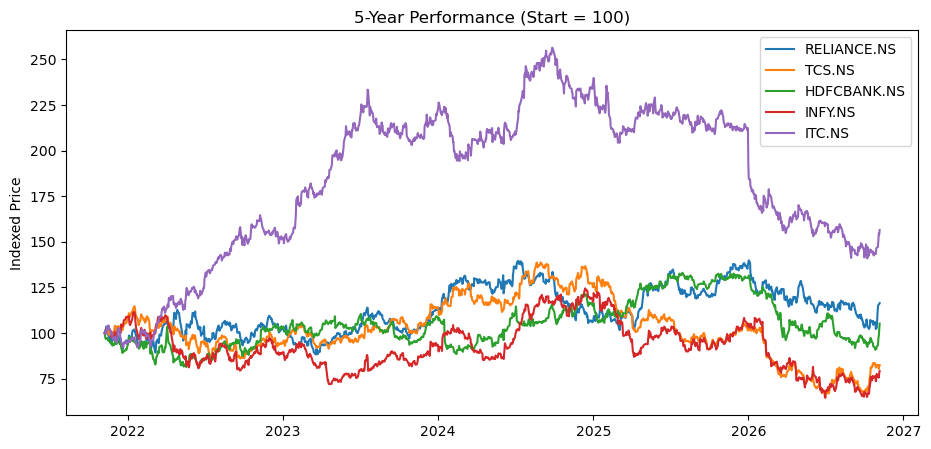

In [6]:
import matplotlib.pyplot as plt

normalized = closes / closes.iloc[0] * 100

plt.figure(figsize=(11, 5))
for s in stocks:
    plt.plot(normalized.index, normalized[s], label=s)
plt.title('5-Year Performance (Start = 100)')
plt.ylabel('Indexed Price')
plt.legend()
plt.show()

In [7]:
returns.corr().round(2)

,RELIANCE.NS,TCS.NS,HDFCBANK.NS,INFY.NS,ITC.NS
RELIANCE.NS,1.00,0.26,0.36,0.24,0.32
TCS.NS,0.26,1.00,0.24,0.74,0.19
HDFCBANK.NS,0.36,0.24,1.00,0.27,0.23
INFY.NS,0.24,0.74,0.27,1.00,0.18
ITC.NS,0.32,0.19,0.23,0.18,1.00


In [8]:
def backtest(stock, short=20, long=50):
    df = pd.DataFrame({'close': closes[stock]})
    df['ret'] = df['close'].pct_change()
    df['ma_short'] = df['close'].rolling(short).mean()
    df['ma_long'] = df['close'].rolling(long).mean()
    df['signal'] = (df['ma_short'] > df['ma_long']).astype(int)
    df['strategy_ret'] = df['signal'].shift(1) * df['ret']
    df = df.dropna()
    df['buy_hold'] = (1 + df['ret']).cumprod()
    df['strategy'] = (1 + df['strategy_ret']).cumprod()
    return df

for s in stocks:
    r = backtest(s)
    bh = (r['buy_hold'].iloc[-1] - 1) * 100
    st = (r['strategy'].iloc[-1] - 1) * 100
    print(f"{s:12} Buy&Hold: {bh:6.1f}%  |  Strategy: {st:6.1f}%")

RELIANCE.NS  Buy&Hold:   14.8%  |  Strategy:    1.5%
TCS.NS       Buy&Hold:  -27.3%  |  Strategy:  -31.7%
HDFCBANK.NS  Buy&Hold:    9.0%  |  Strategy:  -30.4%
INFY.NS      Buy&Hold:  -28.7%  |  Strategy:  -19.8%
ITC.NS       Buy&Hold:   61.5%  |  Strategy:   83.9%


In [9]:
def max_drawdown(curve):
    return (curve / curve.cummax() - 1).min()

def sharpe(r):
    return r.mean() / r.std() * np.sqrt(252)

rows = []
for s in stocks:
    df = backtest(s)
    pos = df['signal'].shift(1).fillna(0)
    trades = pos.diff().abs().sum()
    cost = 0.001   # 0.1% har trade pe
    net_ret = df['strategy_ret'] - pos.diff().abs().fillna(0) * cost
    net_curve = (1 + net_ret).cumprod()
    rows.append({
        'Stock': s,
        'B&H %': round((df['buy_hold'].iloc[-1] - 1) * 100, 1),
        'Strat %': round((df['strategy'].iloc[-1] - 1) * 100, 1),
        'Strat after cost %': round((net_curve.iloc[-1] - 1) * 100, 1),
        'B&H MaxDD %': round(max_drawdown(df['buy_hold']) * 100, 1),
        'Strat MaxDD %': round(max_drawdown(df['strategy']) * 100, 1),
        'B&H Sharpe': round(sharpe(df['ret']), 2),
        'Strat Sharpe': round(sharpe(df['strategy_ret']), 2),
        'Trades': int(trades)
    })

pd.DataFrame(rows).set_index('Stock')

,B&H %,Strat %,Strat after cost %,B&H MaxDD %,Strat MaxDD %,B&H Sharpe,Strat Sharpe,Trades
Stock,,,,,,,,
RELIANCE.NS,14.8,1.5,-1.7,-27.2,-23.2,0.24,0.09,32
TCS.NS,-27.3,-31.7,-33.7,-53.4,-33.4,-0.18,-0.48,31
HDFCBANK.NS,9.0,-30.4,-32.7,-31.7,-37.9,0.19,-0.42,34
INFY.NS,-28.7,-19.8,-22.0,-48.2,-38.2,-0.14,-0.19,27
ITC.NS,61.5,83.9,81.3,-45.0,-16.9,0.62,1.02,14


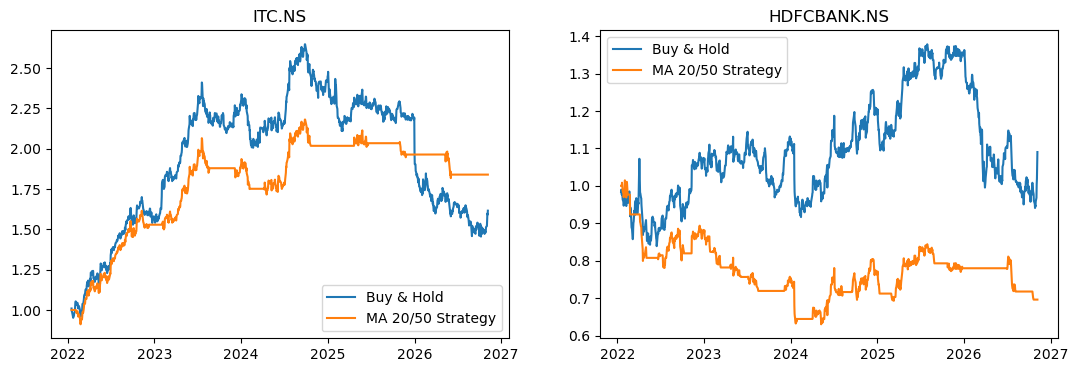

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, s in zip(ax, ['ITC.NS', 'HDFCBANK.NS']):
    r = backtest(s)
    a.plot(r.index, r['buy_hold'], label='Buy & Hold')
    a.plot(r.index, r['strategy'], label='MA 20/50 Strategy')
    a.set_title(s)
    a.legend()
plt.show()

In [11]:
def trade_stats(stock):
    df = backtest(stock)
    pos = df['signal'].shift(1).fillna(0)
    entry = (pos.diff() == 1)
    trade_id = entry.cumsum()
    in_trade = pos == 1
    t = (1 + df['strategy_ret'][in_trade]).groupby(trade_id[in_trade]).prod() - 1
    wins = t[t > 0]
    losses = t[t <= 0]
    return {
        'Stock': stock,
        'Trades': len(t),
        'Win rate %': round(len(wins) / len(t) * 100, 1),
        'Avg win %': round(wins.mean() * 100, 1),
        'Avg loss %': round(losses.mean() * 100, 1),
        'Expected value / trade %': round(t.mean() * 100, 2)
    }

pd.DataFrame([trade_stats(s) for s in stocks]).set_index('Stock')

,Trades,Win rate %,Avg win %,Avg loss %,Expected value / trade %
Stock,,,,,
RELIANCE.NS,16,31.2,8.7,-3.4,0.36
TCS.NS,16,37.5,3.5,-5.6,-2.20
HDFCBANK.NS,17,29.4,5.9,-5.2,-1.91
INFY.NS,14,35.7,8.8,-6.6,-1.08
ITC.NS,7,57.1,22.9,-5.5,10.74


In [12]:
fig.savefig('itc_vs_hdfc.png', dpi=150, bbox_inches='tight')
pd.DataFrame(rows).set_index('Stock').to_csv('backtest_results.csv')
pd.DataFrame([trade_stats(s) for s in stocks]).set_index('Stock').to_csv('trade_stats.csv')
print("saved")

saved
